# Medical imaging

## Practicum 1: Computed Tomography Image Visualisation & Reconstruction
Oct-Nov 2026
==============================================================================================

In this practicum, you will work with several topics covered in the theory sessions (Block 1). In particular you will (1) simulate a simple and more complex phantoms, (2) apply Radom forward transformation to simulate the computed tomography (CT) projections over a single slice (i.e., sinograms), and (3) reconstruct the original phantom intensity values using different image reconstruction algorithms. In addition, the Shepp–Logan (head) phantom will be used to analyse noise during reconstruction.

### Aims:
- Generate simple and complex phantoms.
- Understand the principles of CT image reconstruction using a fan beam geometry with the aid of ``skimage``.
- Be able to generate and understand image projections (i.e., sinograms).
- Reconstruct slices from simple and more complex objects (i.e., Shepp–Logan phantom) using back projection.
- Analyse and compare reconstructed data with ground truth data.
- Observe the difference between ideal (noise free) and noisy image reconstruction.

``Remember to comment your code and provide some discussion on the results obtained for each section.``



In [2]:
%matplotlib inline

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import radon

In [3]:
!pip install pydicom --quiet

In [5]:
from google.colab import drive

try:
  drive.mount('/content/drive')
except Exception as e:
  print(e)

Mounted at /content/drive


### 1.1 Visualise a lung CT dicom image and create a phantom (2 points)

Open and visualise the Lung CT volume stored at the `LungCT-Diagnosis` accompanied folder. You can use mango viewer, ITK-Snap, etc. Then, using python commands, read each of the indivdual `dcm` images, and display some 2D slices. Some basic image processing might be needed to adjust the contrast/windows level for better visualisation of all tissues. Then, create a 3D phantom with the ribcages based on their HU (e.g., thresholding) and visualise the 3D rendering. Congratulations, you have created your first anthropomorphic phantom!

<img src='https://github.com/sacumesh/medical-imagining-labs/blob/sachiththa/P1/images_4_notebook/LungPhantomImage.png?raw=1' width="400">


<img src='https://github.com/sacumesh/medical-imagining-labs/blob/sachiththa/P1/images_4_notebook/LungPhantomRendering.png?raw=1' width="400">


Data was taken from https://www.cancerimagingarchive.net/collection/lungct-diagnosis/


In [6]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pydicom as pdc
from pydicom.filereader import dcmread
from skimage.exposure import rescale_intensity
from skimage.morphology import ball, binary_opening, binary_closing, remove_small_objects
from skimage.measure import marching_cubes
from scipy.ndimage import gaussian_filter
import plotly.graph_objects as go

In [7]:
# ---------- 1) Read DICOM series ----------
DATA_DIR = Path("/content/drive/MyDrive/Medical Imaging/P1-student/P1-student/LungCT-Diagnosis")  # set to your dataset root

def read_series(dicom_dir: Path):
    files = sorted([p for p in dicom_dir.rglob("*.dcm")])
    assert files, f"No DICOMs under {dicom_dir}"
    # read all headers to sort by position or instance
    metas = []
    for f in files:
        ds = dcmread(str(f), stop_before_pixels=True, force=True)
        z = None
        if hasattr(ds, "ImagePositionPatient"):
            z = float(ds.ImagePositionPatient[2])
        inst = int(getattr(ds, "InstanceNumber", 0))
        metas.append((f, z, inst))
    # prefer ImagePositionPatient for sort, else InstanceNumber
    if all(m[1] is not None for m in metas):
        metas.sort(key=lambda x: x[1])
    else:
        metas.sort(key=lambda x: x[2])

    # insert your code here

    for meta in metas:
      f = meta[0]
      ds = dcmread(f, stop_before_pixels=False, force=True)

      yield ds

In [8]:
# ---------- 2) 2D visualisation with window/level ----------

# insert your code here

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as w
from ipywidgets import interact
from skimage.exposure import rescale_intensity
from functools import partial

# --- build HU volume ------------------------------------------------------
slices = list(read_series(DATA_DIR))
vol_hu = np.stack([ds.pixel_array for ds in slices])  # (n, rows, cols) in HU

def viewer(vol_hu):
    hu_min, hu_max = int(vol_hu.min()), int(vol_hu.max())

    def show(idx, hu):
        lo, hi = hu
        img = rescale_intensity(vol_hu[idx], in_range=(lo, hi),
                                out_range=(lo, hi))
        fig, ax = plt.subplots(figsize=(6, 6))
        im = ax.imshow(img, cmap="gray")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="HU")
        ax.set_title(f"slice {idx}  [{lo}, {hi}] HU")
        ax.axis("off")
        plt.show()

    interact(
        show,
        idx = w.Dropdown(options=list(range(vol_hu.shape[0])), value=vol_hu.shape[0] // 2, description="slice"),
        hu  = w.IntRangeSlider(value=(-160, 240), min=hu_min, max=hu_max, description="HU range",
                               continuous_update=False, layout=w.Layout(width="600px")),
    )

viewer(vol_hu)

interactive(children=(Dropdown(description='slice', index=34, options=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 1…

In [ ]:
# ---------- 3) Ribcage phantom via HU threshold ----------
# Simple bone mask. Typical cortical bone > 300 HU.
vol_hu = vol.astype(np.float32)
BONE_TH = 300.0
bone_mask = vol_hu >= BONE_TH

# insert your code here

import numpy as np
from scipy.ndimage import gaussian_filter
from skimage.morphology import ball, binary_opening, binary_closing, remove_small_objects
from skimage.measure import label


def threshold_bone(vol: np.ndarray, th: float = BONE_TH, sigma: float = 0.5) -> np.ndarray:
    """Smooth lightly, then keep voxels above the HU threshold."""
    return gaussian_filter(vol, sigma) >= th


def clean_mask(mask: np.ndarray, open_r: int = 1, close_r: int = 2, min_size: int = 500) -> np.ndarray:
    """Remove speckle, fill small holes, drop tiny components."""
    mask = binary_opening(mask, ball(open_r))     # kills isolated bright voxels (noise, contrast vessels)
    mask = binary_closing(mask, ball(close_r))    # bridges small gaps in cortical bone
    return remove_small_objects(mask, min_size=min_size)


def keep_largest(mask: np.ndarray, n: int = 1) -> np.ndarray:
    """Keep the n largest connected components (ribcage + spine form one)."""
    labels = label(mask, connectivity=1)
    sizes = np.bincount(labels.ravel())
    sizes[0] = 0                                   # ignore background
    keep = np.argsort(sizes)[::-1][:n]
    return np.isin(labels, keep)


def ribcage_mask(vol: np.ndarray, th: float = BONE_TH) -> np.ndarray:
    return keep_largest(clean_mask(threshold_bone(vol, th)))


bone_mask = ribcage_mask(vol_hu)
print("bone voxels:", bone_mask.sum(), f"({100 * bone_mask.mean():.2f} % of volume)")


bone voxels: 46513 (0.26 % of volume)


In [ ]:
# ---------- 4) 3D rendering with marching cubes ----------
# Marching cubes expects z-y-x ordering and voxel spacing.


# insert your code here
import numpy as np
import plotly.graph_objects as go
from skimage.measure import marching_cubes


def mask_to_mesh(mask: np.ndarray, spacing: np.ndarray, step: int = 1):
    """Surface of a binary mask in mm. Returns (verts (V,3) as z,y,x; faces (F,3))."""
    verts, faces, _, _ = marching_cubes(
        mask.astype(np.uint8), level=0.5,
        spacing=tuple(spacing[0]),          # (dz, dy, dx); validated equal for all slices
        step_size=step,
    )
    return verts, faces


def mesh_figure(verts: np.ndarray, faces: np.ndarray, color: str = "lightgray") -> go.Figure:
    """Interactive plotly figure of one mesh. Axes relabelled to patient x, y, z."""
    z, y, x = verts.T
    mesh = go.Mesh3d(x=x, y=y, z=z,
                     i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
                     color=color, opacity=1.0, flatshading=True,
                     lighting=dict(ambient=0.4, diffuse=0.8, specular=0.2))
    fig = go.Figure(mesh)
    fig.update_layout(
        scene=dict(xaxis_title="x (mm)", yaxis_title="y (mm)", zaxis_title="z (mm)",
                   aspectmode="data"),             # keep true proportions
        width=800, height=800, margin=dict(l=0, r=0, t=0, b=0),
    )
    return fig


verts, faces = mask_to_mesh(bone_mask, spacing, step=2)
print(f"{len(verts):,} vertices, {len(faces):,} faces")
mesh_figure(verts, faces).show()


ValueError: `spacing` must consist of three floats.

### 1.2 Create a simple and homogeneous phantom (1.5 points)

Now create from scratch a more simple 2D phantom which contains a fake (bright) lesion as shown below:

<img src='https://github.com/sacumesh/medical-imagining-labs/blob/sachiththa/P1/images_4_notebook/PhantomImage.png?raw=1' width="400">

- Phantom size: 256 x 256 pixels.
- Phantom must contain 3 tissues:
    - Background = 0 pixel intensity value
    - Tissue 1 = 1 (radius = 100 pixels)
    - Tissue 2 (lesion) = 2 (radius = 5 pixels)
    
Help: To create the circunferences, you can use the function ``create_circular_mask``, or define your own function. The lesion can be placed anywhere within the phantom, except at the exact center.

Once constructed, add a second lesion in the same row (same size and pixel intensity), plot the original phantom and a pixel intensity (horizontal) profile along the synthetic lesions, similarly as shown above (but with two lesions). Always remember to include the units of the axis when ploting a graph.

``Questions``: What challenges did you face? How did you deal with them?

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import radon
from skimage.transform import iradon

In [10]:
def create_circular_mask(h, w, center=None, radius=None):
    if center is None:
        center = (w // 2, h // 2)
    if radius is None:
        radius = min(center[0], center[1], w - center[0], h - center[1])

    # Generate coordinates and calculate Euclidean distance squared to avoid sqrt overhead
    Y, X = np.ogrid[:h, :w]
    dist_squared = (X - center[0]) ** 2 + (Y - center[1]) ** 2
    return dist_squared <= radius ** 2

def fill_circular_segment(canvas, center=None, radius=None, val=0):
    h, w = canvas.shape[:2]
    if center is None:
        center = (w // 2, h // 2)
    if radius is None:
        radius = min(center[0], center[1], w - center[0], h - center[1])

    mask = create_circular_mask(h, w, center, radius)

    # Modify canvas in-place or return a copy cleanly using numpy.where
    return np.where(mask, val, canvas)

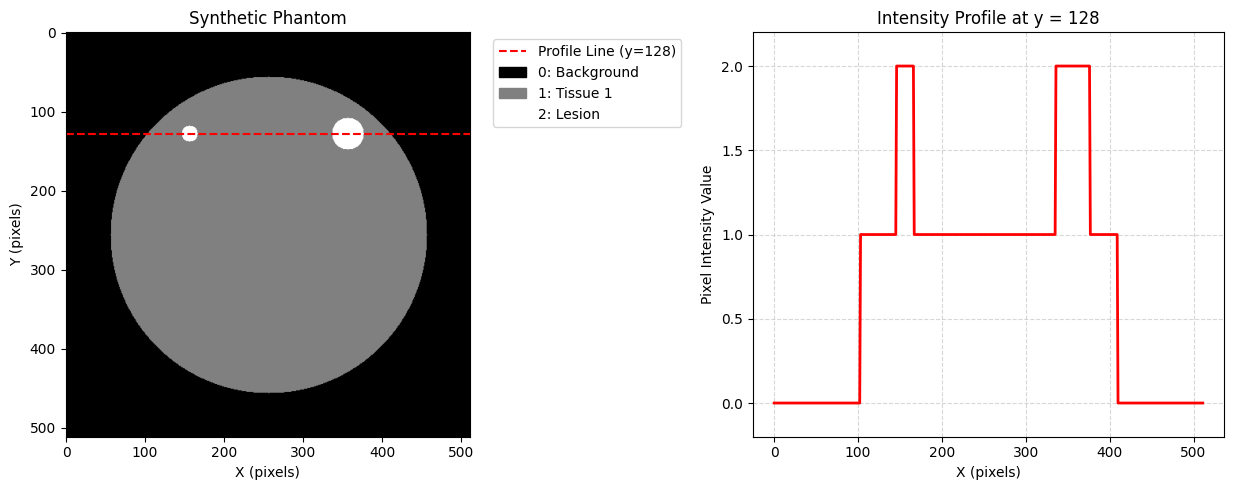

In [11]:
import matplotlib.patches as mpatches

# Central configuration variables
phantom_center_x, phantom_center_y = 256, 256
lesion_y = 128

# Calculate lesion x-coordinates as offsets relative to the phantom center x
lesion_offset = 100
lesion_left_x = phantom_center_x - lesion_offset
lesion_right_x = phantom_center_x + lesion_offset

# Create the base phantom background and primary tissue structure
phantom = create_circular_mask(512, 512, center=(phantom_center_x, phantom_center_y), radius=200).astype(float)

# Clean configuration for the lesions (tissue 2)
lesions = [
    {"center": (lesion_left_x, lesion_y), "radius": 10, "val": 2},
    {"center": (lesion_right_x, lesion_y), "radius": 20, "val": 2}
]

# Fill lesions sequentially
for lesion in lesions:
    phantom = fill_circular_segment(phantom, **lesion)

# Extract the 1D pixel intensity profile along the lesion line (y = lesion_y)
profile = phantom[lesion_y, :]

# Create subplots side-by-side with extra width for the legend
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5))

# Left Plot: Synthetic Phantom
im = ax1.imshow(phantom, cmap='gray', vmin=0, vmax=2)
ax1.set_title("Synthetic Phantom")
line_handle = ax1.axhline(y=lesion_y, color='red', linestyle='--', linewidth=1.5, label=f'Profile Line (y={lesion_y})')
ax1.set_xlabel("X (pixels)")
ax1.set_ylabel("Y (pixels)")

# Create custom legend handles for tissue types
bg_patch = mpatches.Patch(color='black', label='0: Background')
tissue1_patch = mpatches.Patch(color='gray', label='1: Tissue 1')
lesion_patch = mpatches.Patch(color='white', label='2: Lesion')

# Place the legend cleanly outside the plot boundary to prevent any overlapping
ax1.legend(
    handles=[line_handle, bg_patch, tissue1_patch, lesion_patch],
    loc='upper left',
    bbox_to_anchor=(1.04, 1),
    framealpha=0.8
)
ax1.axis('on')

# Right Plot: Pixel Intensity Profile
ax2.plot(profile, color='red', linewidth=2)
ax2.set_title(f"Intensity Profile at y = {lesion_y}")
ax2.set_xlabel("X (pixels)")
ax2.set_ylabel("Pixel Intensity Value")
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.set_ylim(-0.2, 2.2)

plt.tight_layout()
plt.show()

### 1.3 Create the projections of the phantom (2 points)

Generate the projections of the previously generated 2D phantom using the ``radon`` transform from ``skimage.transform``. Play with the different parameters to optimise sinogram. Then, show the sinogram of the projections.

In this section, considered the following approch:

Use different number of projections (i.e. 4, 20, 50, 100, 200, 300, 360) considering that in all cases the simulated projections cover the 360º. For example, 100 projections are taken in the range from 0º to 360º.


``Questions``: How do the sinograms changes with number of projections? What is the effect of increasing/decrasing the number of projections?

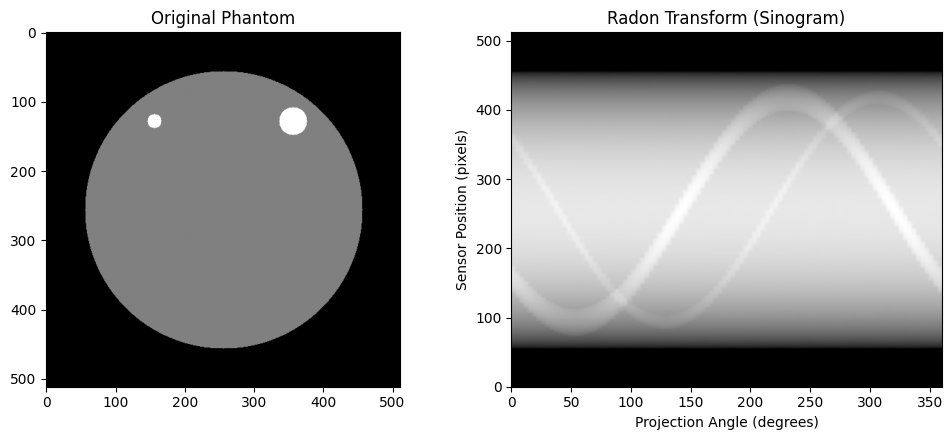

In [30]:
from skimage.transform import radon

# Configuration parameters
n_projections = 100
theta = np.linspace(0.0, 360.0, n_projections, endpoint=True)

# Compute the forward Radon transform (sinogram)
sinogram = radon(phantom, theta=theta)

# Visualize the original phantom alongside its sinogram
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))

# Original Phantom Plot
ax1.set_title("Original Phantom")
ax1.imshow(phantom, cmap='gray')
ax1.axis('on')

# Sinogram Plot
ax2.set_title("Radon Transform (Sinogram)")
ax2.set_xlabel("Projection Angle (degrees)")
ax2.set_ylabel("Sensor Position (pixels)")

# Display sinogram with projection angles properly mapped on the x-axis
im = ax2.imshow(
    sinogram,
    cmap='gray',
    extent=(0.0, 360.0, 0, sinogram.shape[0]),
    aspect='auto'
)

plt.tight_layout()
plt.show()

### 1.4 Reconstruction with Filtered Back Projection (FBP) (2.5 points)

FBP is one of the most simple reconstruction methods to reconstruct images in CT. Explore the ``iradon`` from ``skimage.transform`` using the different filters available (Ramp filter (default), Shepp-logan, Cosine, Hamming, Hann).

Make use of the ``matplotlib`` to show the original and reconstructed images of the phantom and compare the pixel intensity signal across the lesion profile (similarly to section 2.1).In addition, provide evaluation metric you could consider useful for this purpose (image difference, mean square error (MSE), peak signal to noise ratio (PSNR), structural index similarity (SSIM), etc.). Then, discuss the results.

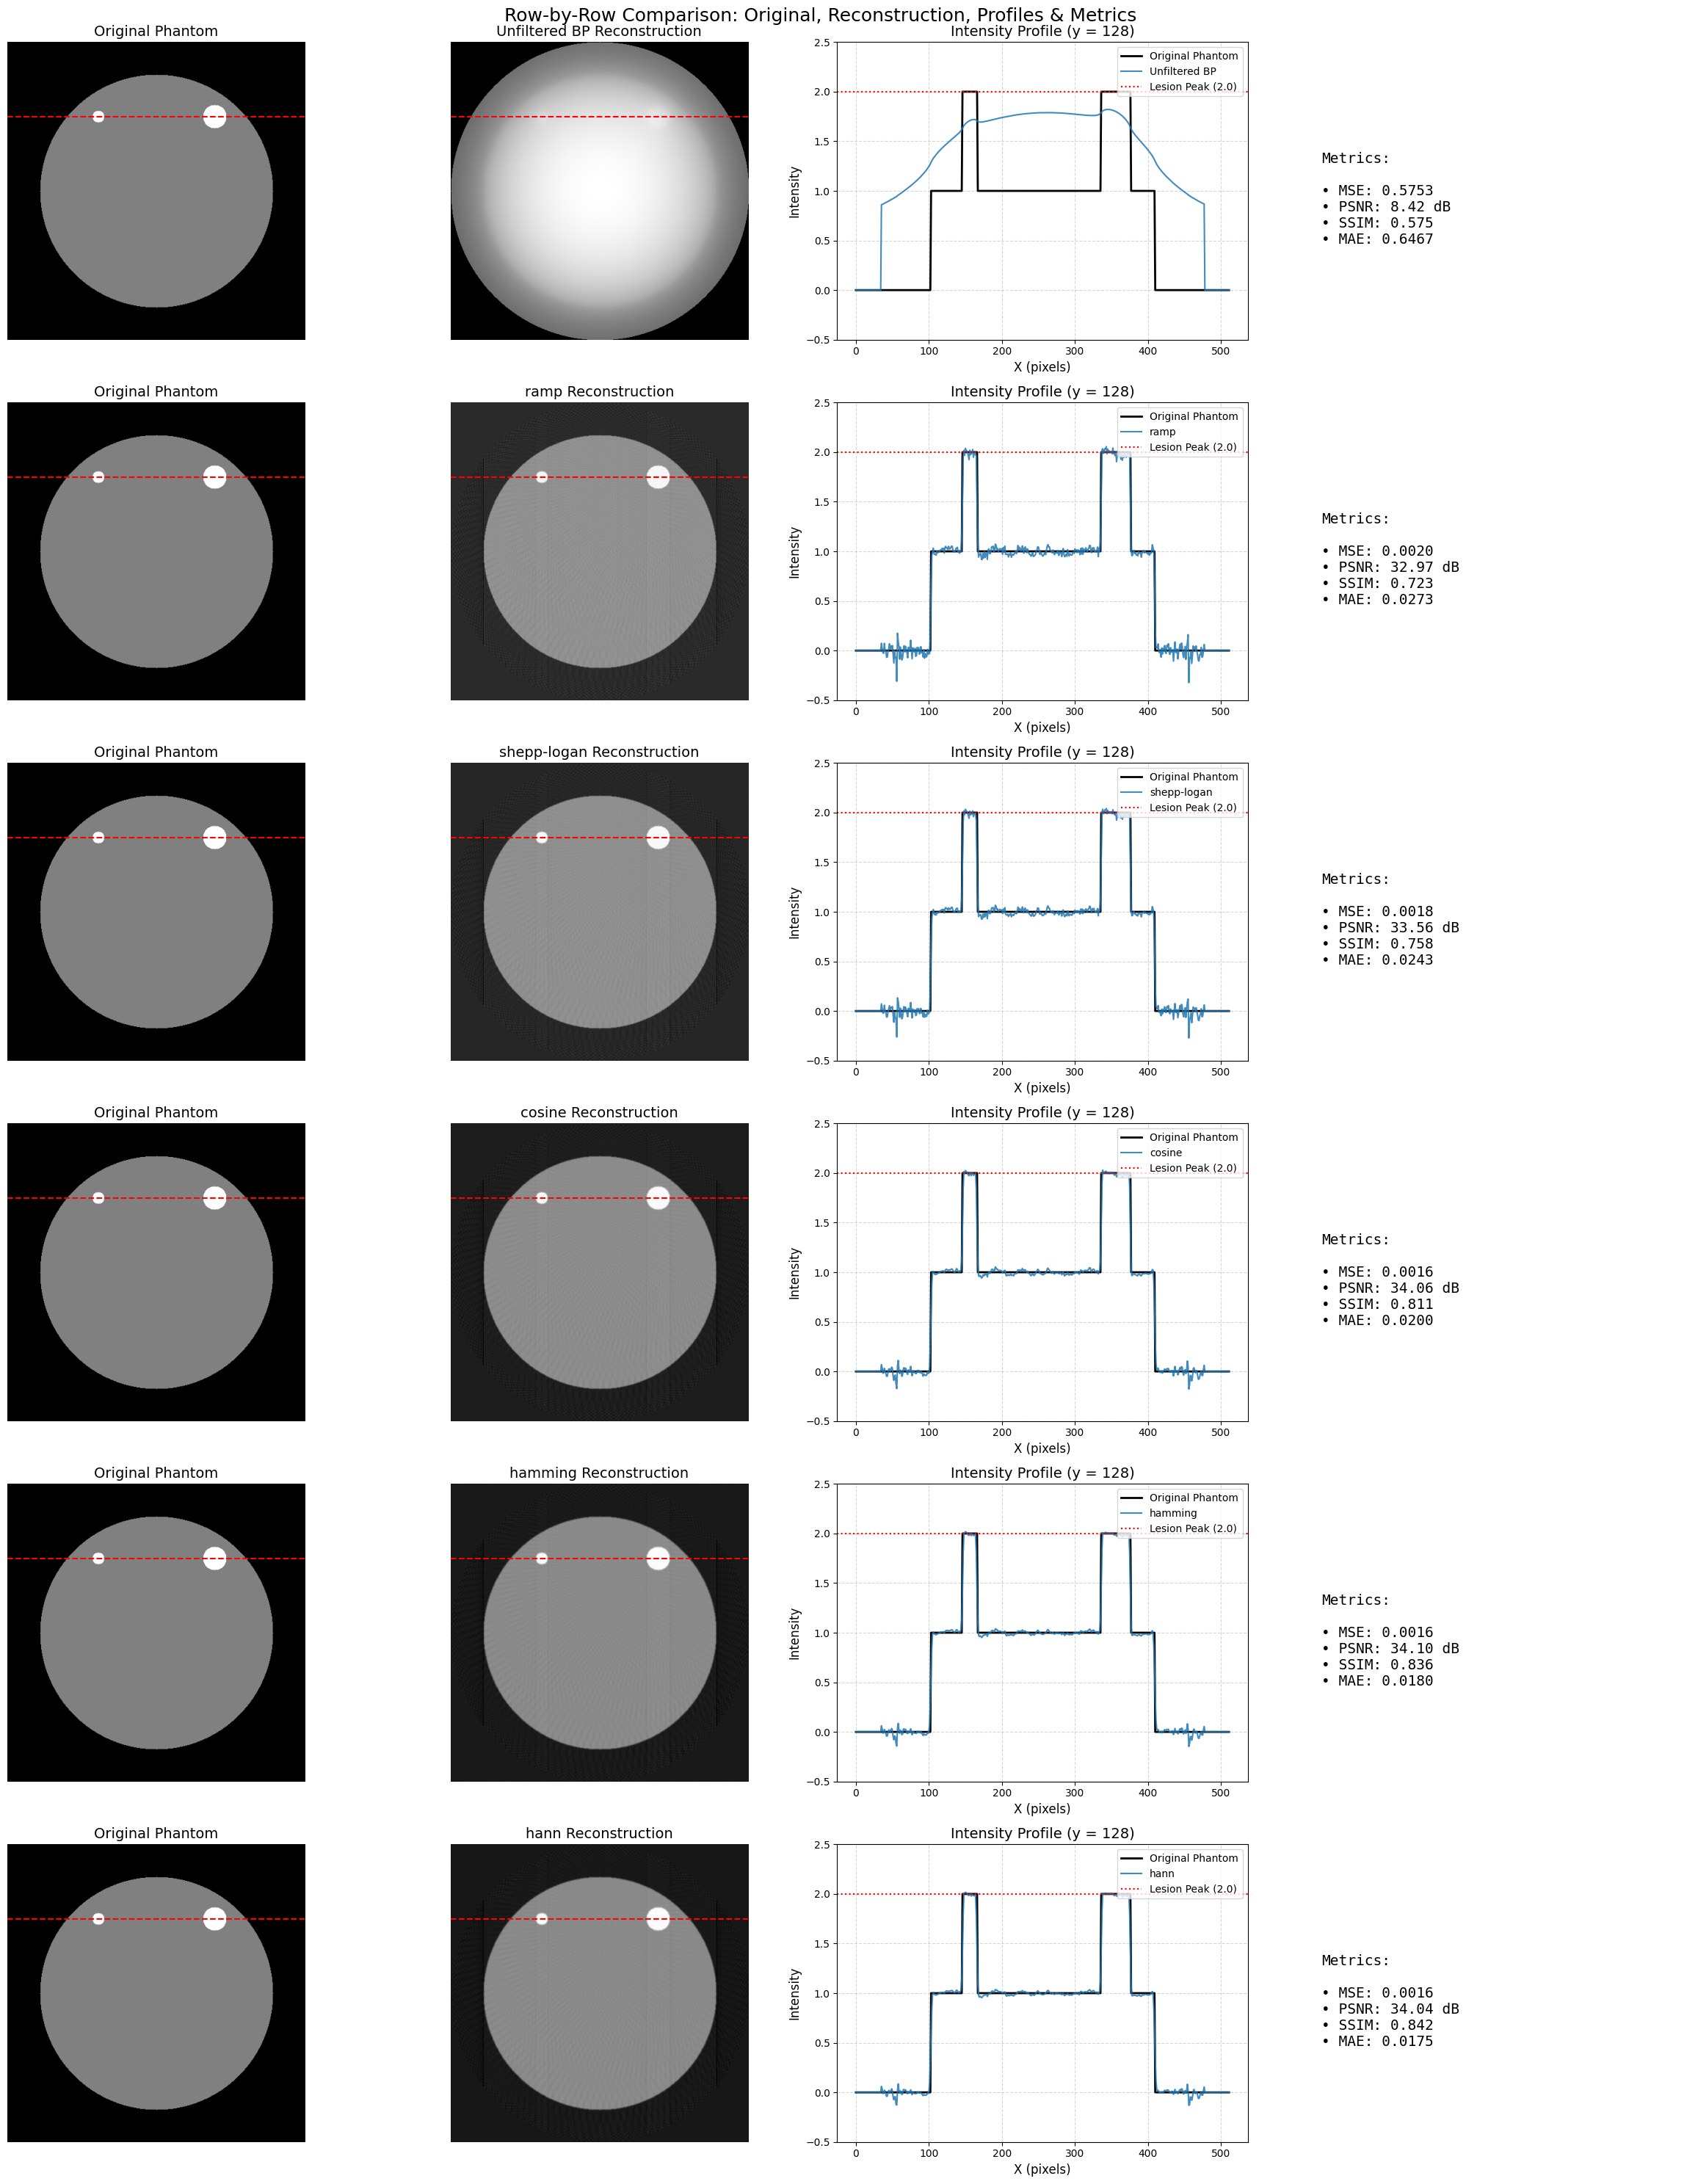

In [49]:
from skimage.transform import iradon
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import mean_squared_error as mse
import numpy as np
import matplotlib.pyplot as plt

# Configure angle range (0 to 360 degrees for n_projections)
n_projections = 100
theta = np.linspace(0.0, 360.0, n_projections, endpoint=True)

# Compute forward Radon transform (sinogram)
sinogram = radon(phantom, theta=theta)

# Get target size from phantom to match reconstruction output
N_size = phantom.shape[0]

# Dynamic data range for proper metric calculation
d_range = phantom.max() - phantom.min()

# Define filters to evaluate
FILTERS = ["ramp", "shepp-logan", "cosine", "hamming", "hann"]
recons = {}
metrics = {}

# Perform Filtered Back-Projection (FBP) for each filter
for f in FILTERS:
    rec = iradon(sinogram, theta=theta, filter_name=f, output_size=N_size)
    recons[f] = rec
    metrics[f] = {
        "mse": mse(phantom, rec),
        "psnr": psnr(phantom, rec, data_range=d_range),
        "ssim": ssim(phantom, rec, data_range=d_range),
        "mae": np.mean(np.abs(phantom - rec))
    }

# Compute unfiltered back-projection as baseline reference
bp = iradon(sinogram, theta=theta, filter_name=None, output_size=N_size)

# Rescale unfiltered BP to range [0, 2] as requested
bp = 2.0 * (bp - np.min(bp)) / (np.max(bp) - np.min(bp))

# Calculate metrics for Unfiltered BP as well with the rescaled data
metrics["Unfiltered BP"] = {
    "mse": mse(phantom, bp),
    "psnr": psnr(phantom, bp, data_range=d_range),
    "ssim": ssim(phantom, bp, data_range=d_range),
    "mae": np.mean(np.abs(phantom - bp))
}

# Combine all reconstructions into a dictionary
all_recons = {"Unfiltered BP": bp}
all_recons.update(recons)

# Create a structured layout: 4 columns per row
n_rows = len(all_recons)
# Increased plot size for better visibility
fig, axes = plt.subplots(n_rows, 4, figsize=(24, 5 * n_rows))

for idx, (name, rec_img) in enumerate(all_recons.items()):
    # Column 1: Original Phantom
    ax_orig = axes[idx, 0]
    ax_orig.imshow(phantom, cmap="gray")
    ax_orig.axhline(y=lesion_y, color="red", linestyle="--", linewidth=1.5)
    ax_orig.set_title("Original Phantom", fontsize=14)
    ax_orig.axis("off")

    # Column 2: Reconstruction Image
    ax_rec = axes[idx, 1]
    ax_rec.imshow(rec_img, cmap="gray")
    ax_rec.axhline(y=lesion_y, color="red", linestyle="--", linewidth=1.5)
    ax_rec.set_title(f"{name} Reconstruction", fontsize=14)
    ax_rec.axis("off")

    # Column 3: Pixel Intensity Profile
    ax_prof = axes[idx, 2]
    ax_prof.plot(phantom[lesion_y, :], label="Original Phantom", color="black", linewidth=2.0)
    ax_prof.plot(rec_img[lesion_y, :], label=f"{name}", color="tab:blue", linestyle="-", alpha=0.85)
    ax_prof.axhline(y=2.0, color="red", linestyle=":", linewidth=1.5, label="Lesion Peak (2.0)")

    ax_prof.set_title(f"Intensity Profile (y = {lesion_y})", fontsize=14)
    ax_prof.set_xlabel("X (pixels)", fontsize=12)
    ax_prof.set_ylabel("Intensity", fontsize=12)

    # Apply the same uniform limits to all plots since Unfiltered BP is rescaled
    ax_prof.set_ylim(-0.5, 2.5)

    ax_prof.grid(True, linestyle="--", alpha=0.5)
    ax_prof.legend(loc="upper right", fontsize=10)

    # Column 4: Metrics as point forms
    ax_met = axes[idx, 3]
    ax_met.axis("off")
    if name in metrics:
        m = metrics[name]
        text_str = (
            f"\nMetrics:\n\n"
            f"• MSE: {m['mse']:.4f}\n"
            f"• PSNR: {m['psnr']:.2f} dB\n"
            f"• SSIM: {m['ssim']:.3f}\n"
            f"• MAE: {m['mae']:.4f}"
        )
        ax_met.text(0.1, 0.5, text_str, fontsize=14, va='center', ha='left', family='monospace')

plt.suptitle("Row-by-Row Comparison: Original, Reconstruction, Profiles & Metrics", fontsize=18, y=0.99)
plt.tight_layout()
plt.show()

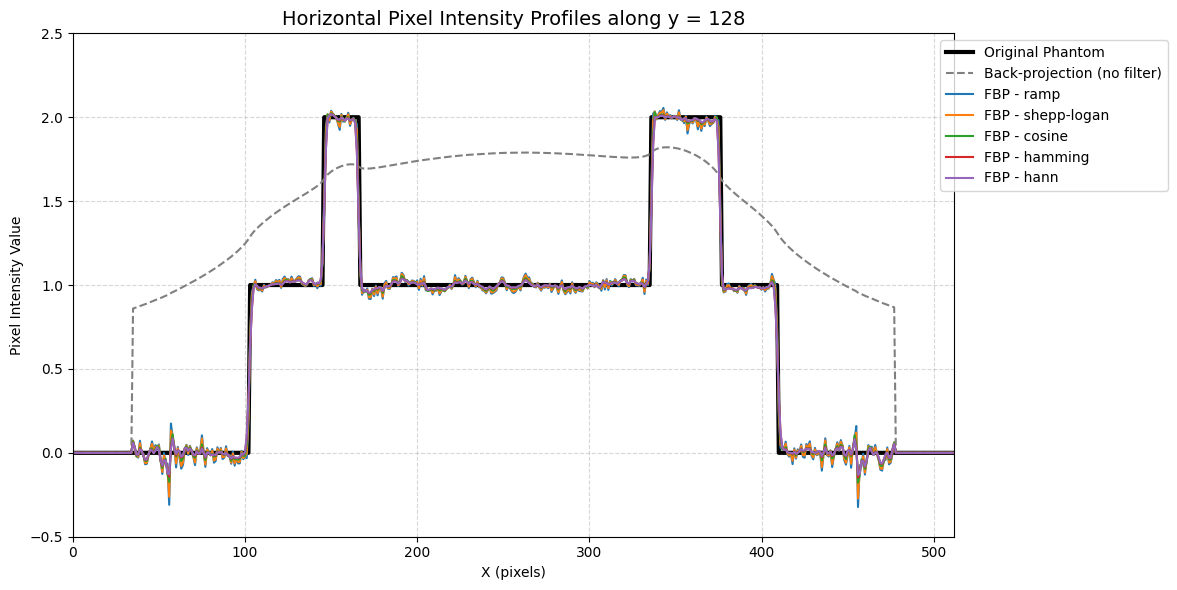

In [47]:
# Plot the 1D pixel intensity profiles along the lesion line (y = 128) on a single plot
plt.figure(figsize=(12, 6))

# Original Phantom Profile
plt.plot(phantom[lesion_y, :], label="Original Phantom", color="black", linewidth=3.0, linestyle="-")

# Unfiltered Back-projection Profile
plt.plot(bp[lesion_y, :], label="Back-projection (no filter)", color="gray", linewidth=1.5, linestyle="--")

# Filtered Reconstructions Profiles
for f in FILTERS:
    plt.plot(recons[f][lesion_y, :], label=f"FBP - {f}", linewidth=1.5)

plt.title(f"Horizontal Pixel Intensity Profiles along y = {lesion_y}", fontsize=14)
plt.xlabel("X (pixels)")
plt.ylabel("Pixel Intensity Value")
plt.legend(loc="upper right", bbox_to_anchor=(1.25, 1))
plt.grid(True, linestyle="--", alpha=0.5)
plt.xlim(0, phantom.shape[1])
plt.ylim(-0.5, 2.5)
plt.tight_layout()
plt.show()

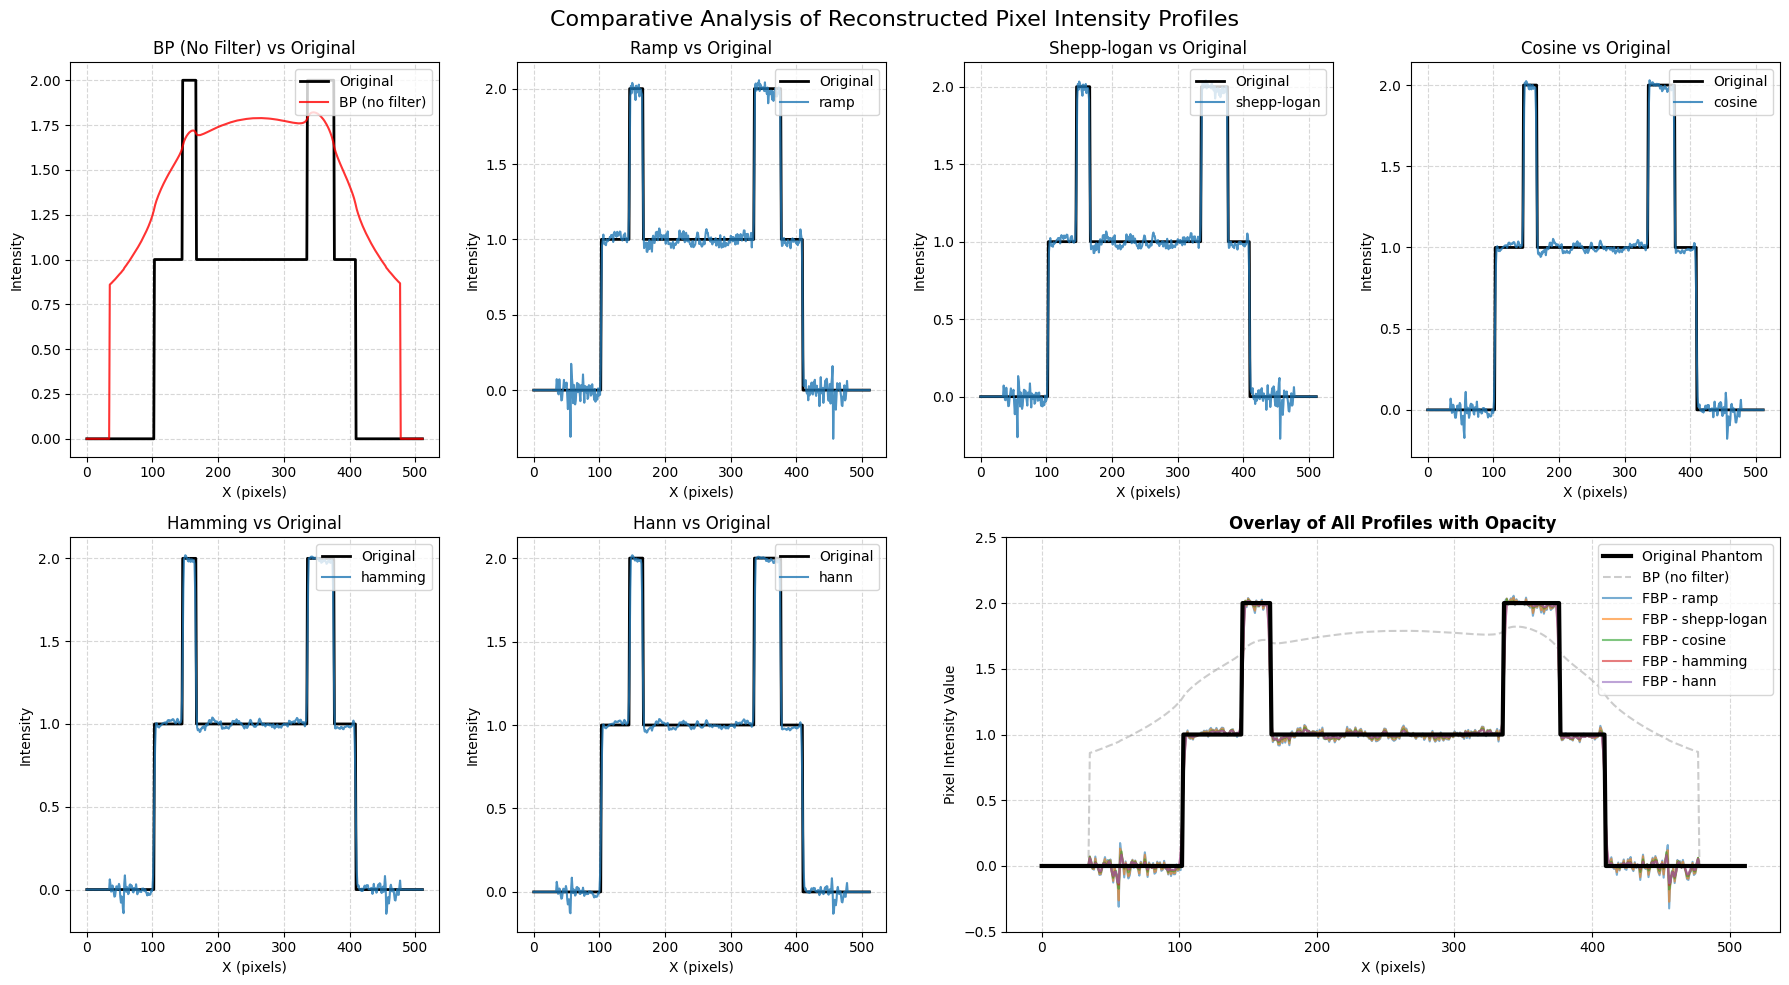

In [48]:
import matplotlib.pyplot as plt

# Configure a grid layout: 2 rows by 3 columns
# This allows 1 plot for the unfiltered back-projection, 5 plots for each filter,
# and 1 large overlay plot at the end.
fig = plt.figure(figsize=(18, 10))

# 1. Individual subplots comparing each reconstruction to the ground truth
# Plot Unfiltered BP
ax1 = plt.subplot(2, 4, 1)
ax1.plot(phantom[lesion_y, :], label="Original", color="black", linewidth=2)
ax1.plot(bp[lesion_y, :], label="BP (no filter)", color="red", alpha=0.8)
ax1.set_title("BP (No Filter) vs Original")
ax1.set_xlabel("X (pixels)")
ax1.set_ylabel("Intensity")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right")

# Plot Filtered Reconstructions
for idx, f in enumerate(FILTERS, start=2):
    ax = plt.subplot(2, 4, idx)
    ax.plot(phantom[lesion_y, :], label="Original", color="black", linewidth=2)
    ax.plot(recons[f][lesion_y, :], label=f, alpha=0.8)
    ax.set_title(f"{f.capitalize()} vs Original")
    ax.set_xlabel("X (pixels)")
    ax.set_ylabel("Intensity")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper right")

# 2. Large final subplot overlaying all profiles with custom opacities
ax_overlay = plt.subplot(2, 2, 4)  # Span across a larger bottom-right corner
ax_overlay.plot(phantom[lesion_y, :], label="Original Phantom", color="black", linewidth=3.0, zorder=10)
ax_overlay.plot(bp[lesion_y, :], label="BP (no filter)", color="gray", alpha=0.4, linestyle="--")

# Cycle through filters and plot with opacity (alpha)
for f in FILTERS:
    ax_overlay.plot(recons[f][lesion_y, :], label=f"FBP - {f}", alpha=0.6, linewidth=1.5)

ax_overlay.set_title("Overlay of All Profiles with Opacity", fontsize=12, fontweight="bold")
ax_overlay.set_xlabel("X (pixels)")
ax_overlay.set_ylabel("Pixel Intensity Value")
ax_overlay.grid(True, linestyle="--", alpha=0.5)
ax_overlay.set_ylim(-0.5, 2.5)
ax_overlay.legend(loc="upper right")

plt.suptitle("Comparative Analysis of Reconstructed Pixel Intensity Profiles", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

### 1.5 Sheep logan phantom (2 points)

So far we have used a quite simple phantom with only 2 tissues. Now, repeat the prior analysis for the **noisy sinogram** for one case (approach, filter,...) using a (slightly) more advanced head test object, the Sheep-logan phantom. Do you observe particular differences between the reconstrucction results from both phantoms?


<img src='https://github.com/sacumesh/medical-imagining-labs/blob/sachiththa/P1/images_4_notebook/SheepLoganPhantom.png?raw=1' width="1000">



In order to create **noisy sinograms**, you can add Poison noise (``np.random.poisson``; perhaps with lam = 10) to your noise-free sinograms (not to the image!) and reconstruct the phantom images with the different filters. Plot the reconstruction image and the (horizontal) intensity profile along specific row. Then, comment on the effects of the filters on the reconstructed phatom images.


In [ ]:
from skimage.data import shepp_logan_phantom

logan_phantom = shepp_logan_phantom()


# insert your code here



###  Generative AI Declaration Policy
If generative AI tools were used in completing this practicum, you must explicitly declare their use. If you used AI, please include response the following three points:
1. ``Purpose``: A brief explanation of what you used generative AI for (e.g., brainstorming, proofreading, code debugging, or structuring ideas).
2. ``Sample Prompt``: At least one example of a prompt you submitted to the AI.
3. ``Refinement Process``: A short description of how you handled the prompt and evaluated the output (e.g., how you verified the facts, refined the wording, or altered the prompt to get better results).

In [ ]:
# answer here



### Group Organisation and Contribution

Since this assignment is a group project, your team must include a text addressing the following three points:
1. ``Task Organization``: Describe how your team organised the workflow to complete the entire notebook (e.g., who was responsible for which sections, how you collaborated, and how you merged your work).

2. ``Conflict Resolution``: Explain how you handled any discrepancies, disagreements, or differing opinions regarding the project's technical approach or final answers.

3. ``Percentage Contribution``: State the exact percentage of effort and contribution made by each member. The total sum across all three members must equal exactly 100% (e.g., Member A: 33.333%, Member B: 33.333%, Member C: 33.333%).


In [ ]:
# answer here

